# MetroPT-3 EDA (spec 001)

Logic lives in `src/railguard`; this notebook only calls it. Unlabelled rows are **unknown**, not healthy. Timestamps are naive local time.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from railguard.data.labels import FAILURE, assign_labels, load_failure_windows
from railguard.data.metropt3 import (
    ANALOG_COLUMNS,
    DIGITAL_COLUMNS,
    load_metropt3,
    validate_metropt3,
)
from railguard.preprocessing.quality import quality_report
from railguard.preprocessing.segments import assign_segments

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
CSV = ROOT / "datasets/raw/metropt+3+dataset/MetroPT3(AirCompressor).csv"
SHA = "db30ccb4ea402e3c8bf2c99db06e288d4f2a772f6928f9dbe26a920d69793e24"
HORIZON = pd.Timedelta(hours=24)  # configurable assumption, not a fact

In [2]:
df, meta = load_metropt3(CSV, SHA)
validate_metropt3(df)
windows = load_failure_windows(ROOT / "configs/metropt3_failure_windows.yaml")
df["segment_id"] = assign_segments(df["timestamp"], 60.0)
df["label"] = assign_labels(df["timestamp"], windows, HORIZON)
report = quality_report(df.drop(columns=["segment_id", "label"]), digital_columns=DIGITAL_COLUMNS)
print(meta.rows, "rows;", report.gap_count, "gaps >60 s;", report.gap_count_over_1h, "gaps >1 h")
print("interval seconds:", report.interval_seconds)
df["label"].value_counts()

1516948 rows; 331 gaps >60 s; 160 gaps >1 h
interval seconds: {'p1': 9.0, 'p50': 10.0, 'p99': 12.0}


label
unlabelled_or_unknown        1458326
documented_failure_window      29954
pre_event_window               28668
Name: count, dtype: int64

## Gap timeline

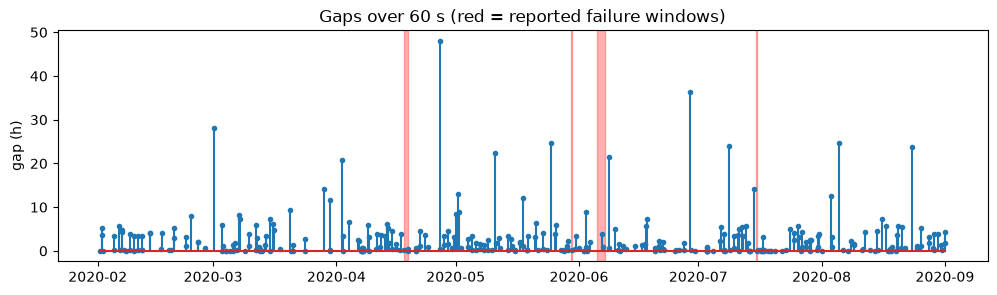

In [3]:
gaps = pd.DataFrame(report.gaps)
gaps["end"] = pd.to_datetime(gaps["end"])
fig, ax = plt.subplots(figsize=(12, 3))
ax.stem(gaps["end"], gaps["seconds"] / 3600, markerfmt=".")
for w in windows:
    ax.axvspan(w.start, w.end, color="red", alpha=0.3)
ax.set_ylabel("gap (h)")
ax.set_title("Gaps over 60 s (red = reported failure windows)")
plt.show()

## Analogue signals over the full period (1-hour means)

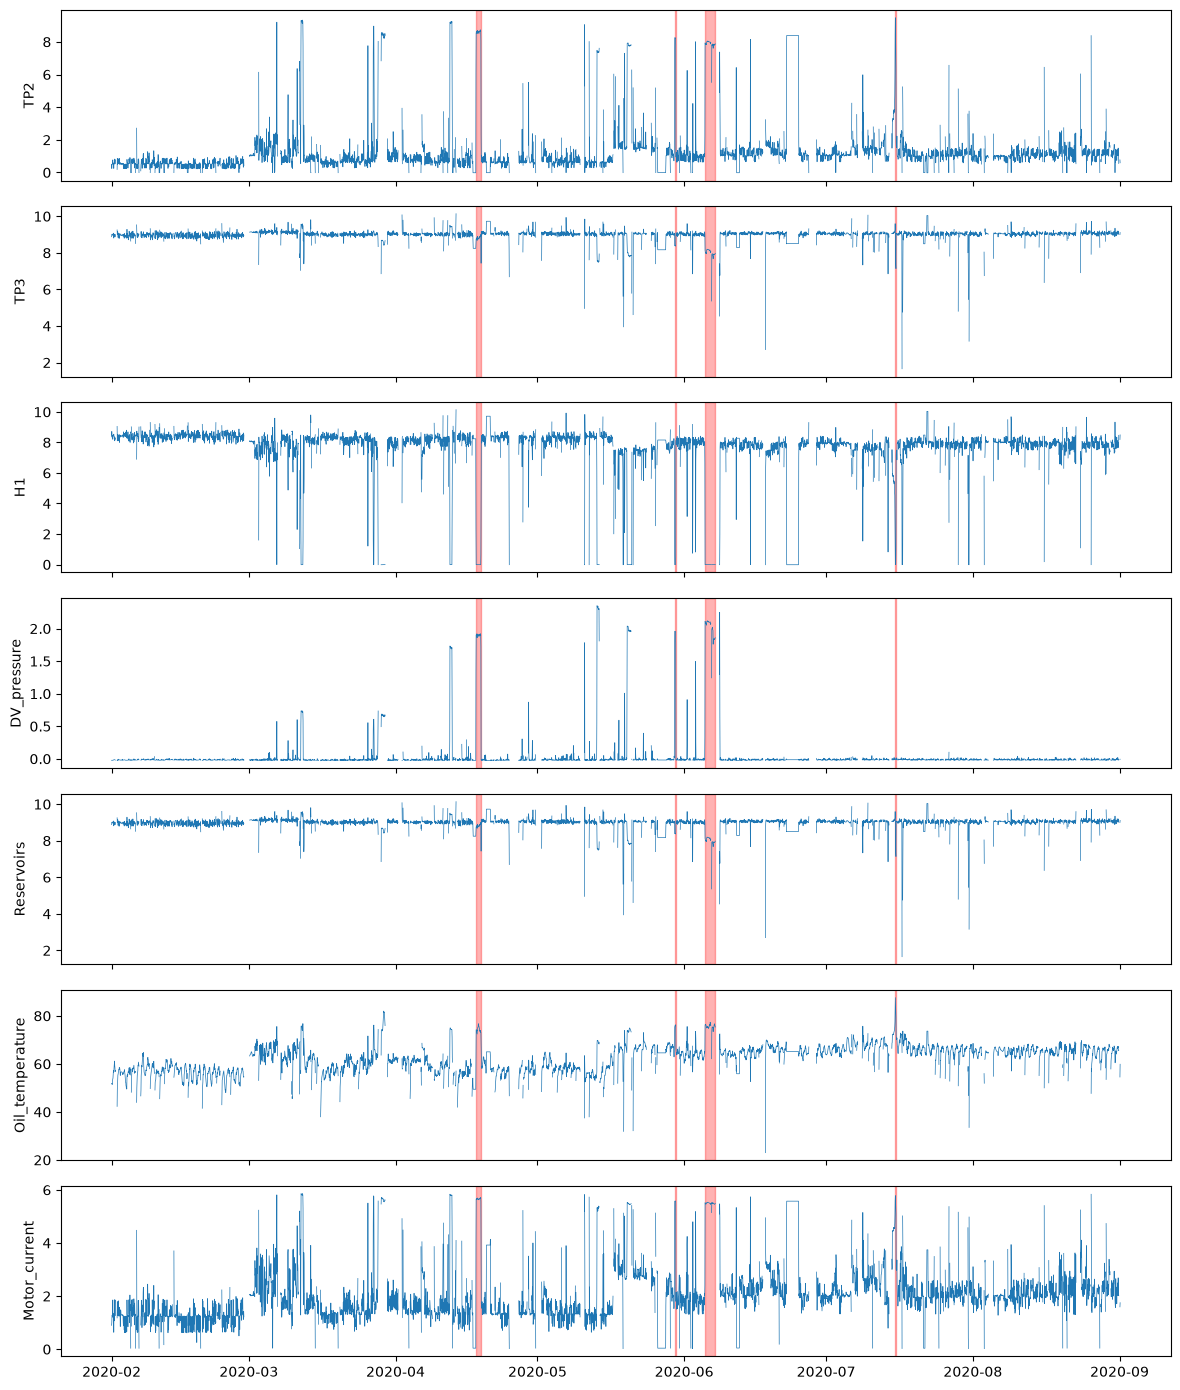

In [4]:
hourly = df.set_index("timestamp")[list(ANALOG_COLUMNS)].resample("1h").mean()
fig, axes = plt.subplots(len(ANALOG_COLUMNS), 1, figsize=(12, 14), sharex=True)
for ax, col in zip(axes, ANALOG_COLUMNS, strict=True):
    ax.plot(hourly.index, hourly[col], lw=0.5)
    for w in windows:
        ax.axvspan(w.start, w.end, color="red", alpha=0.3)
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

## Around each event window (±24 h)

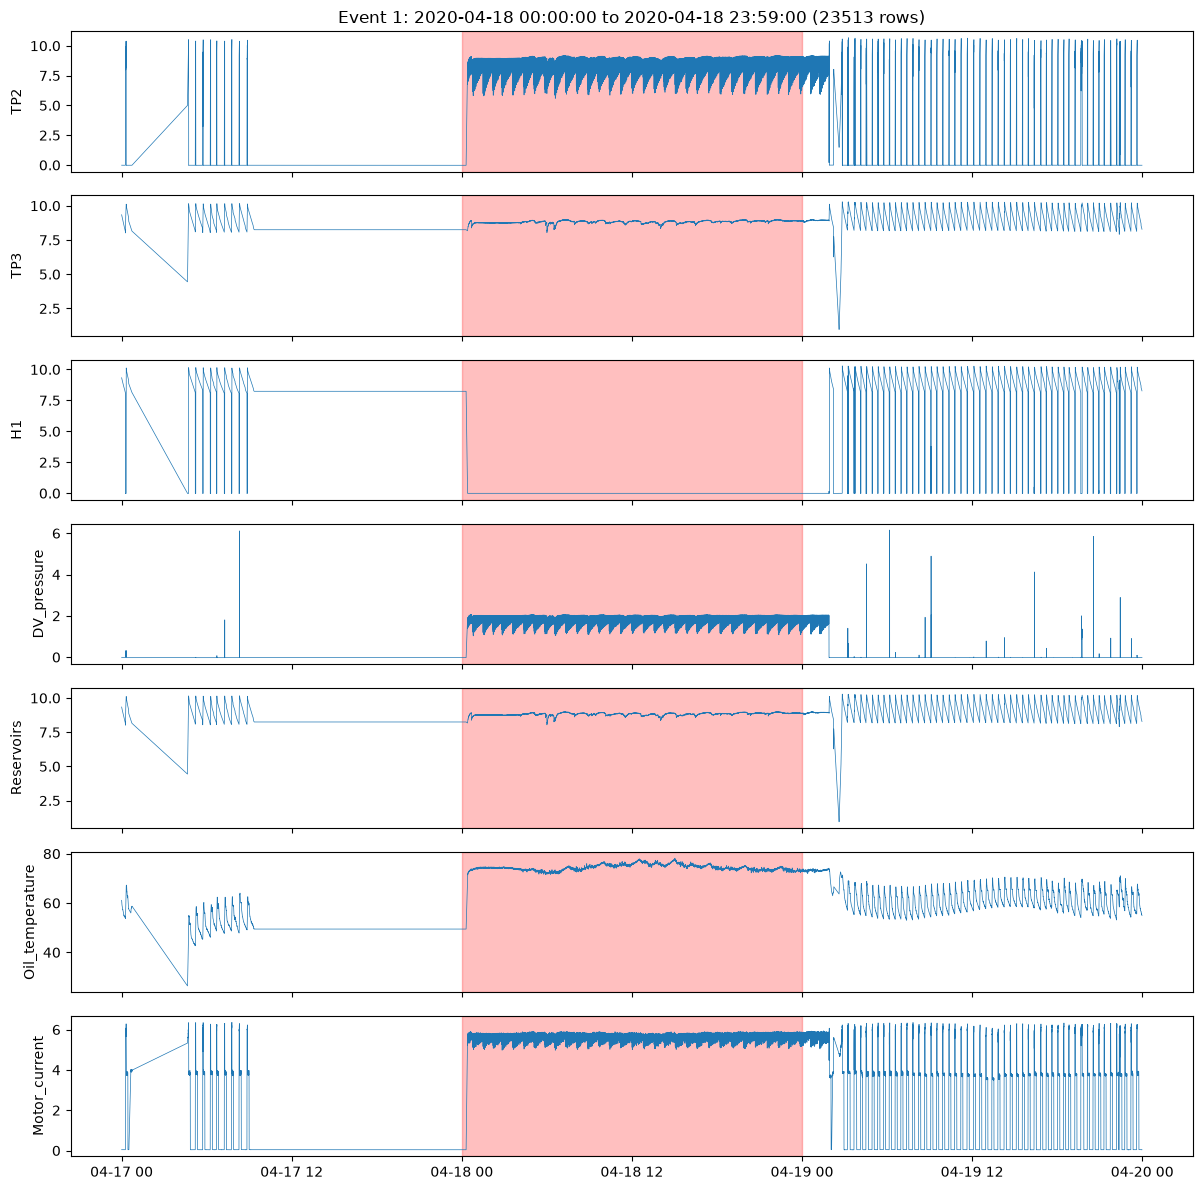

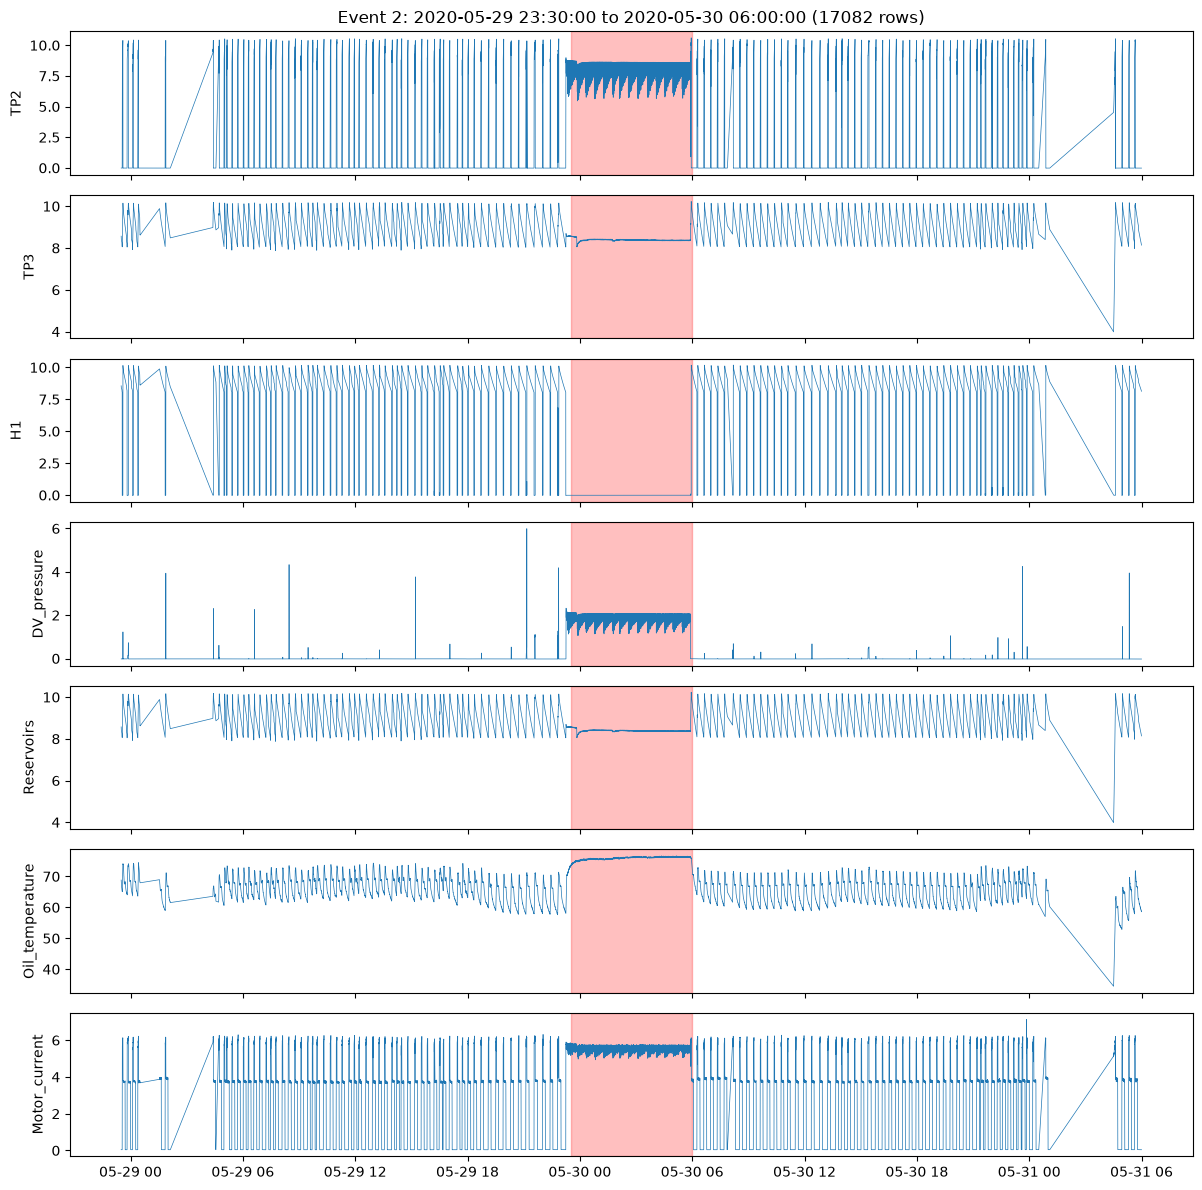

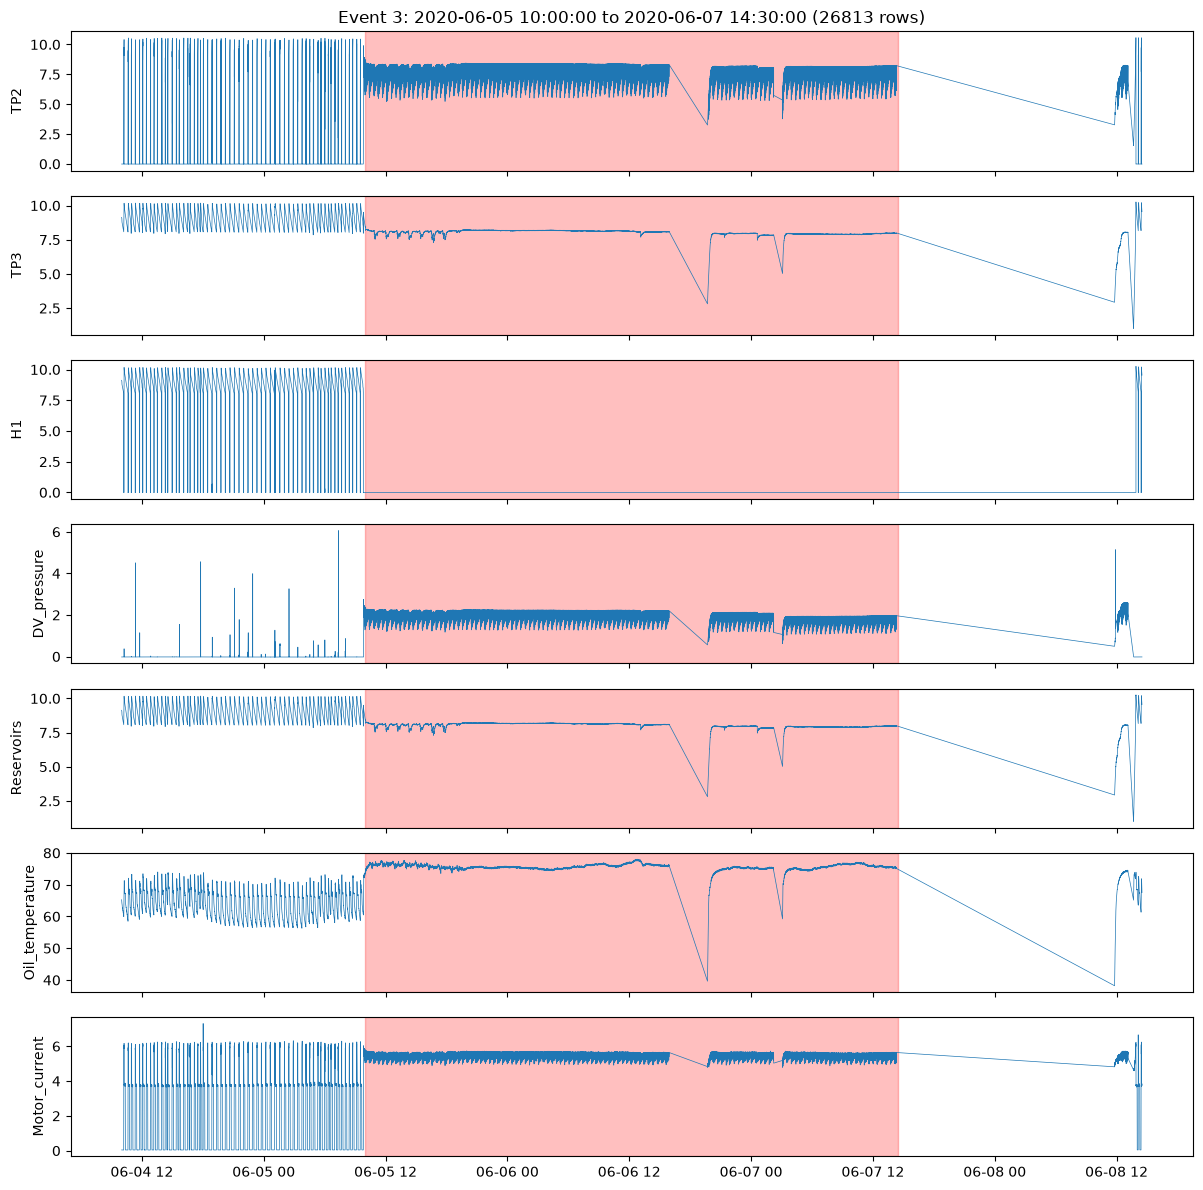

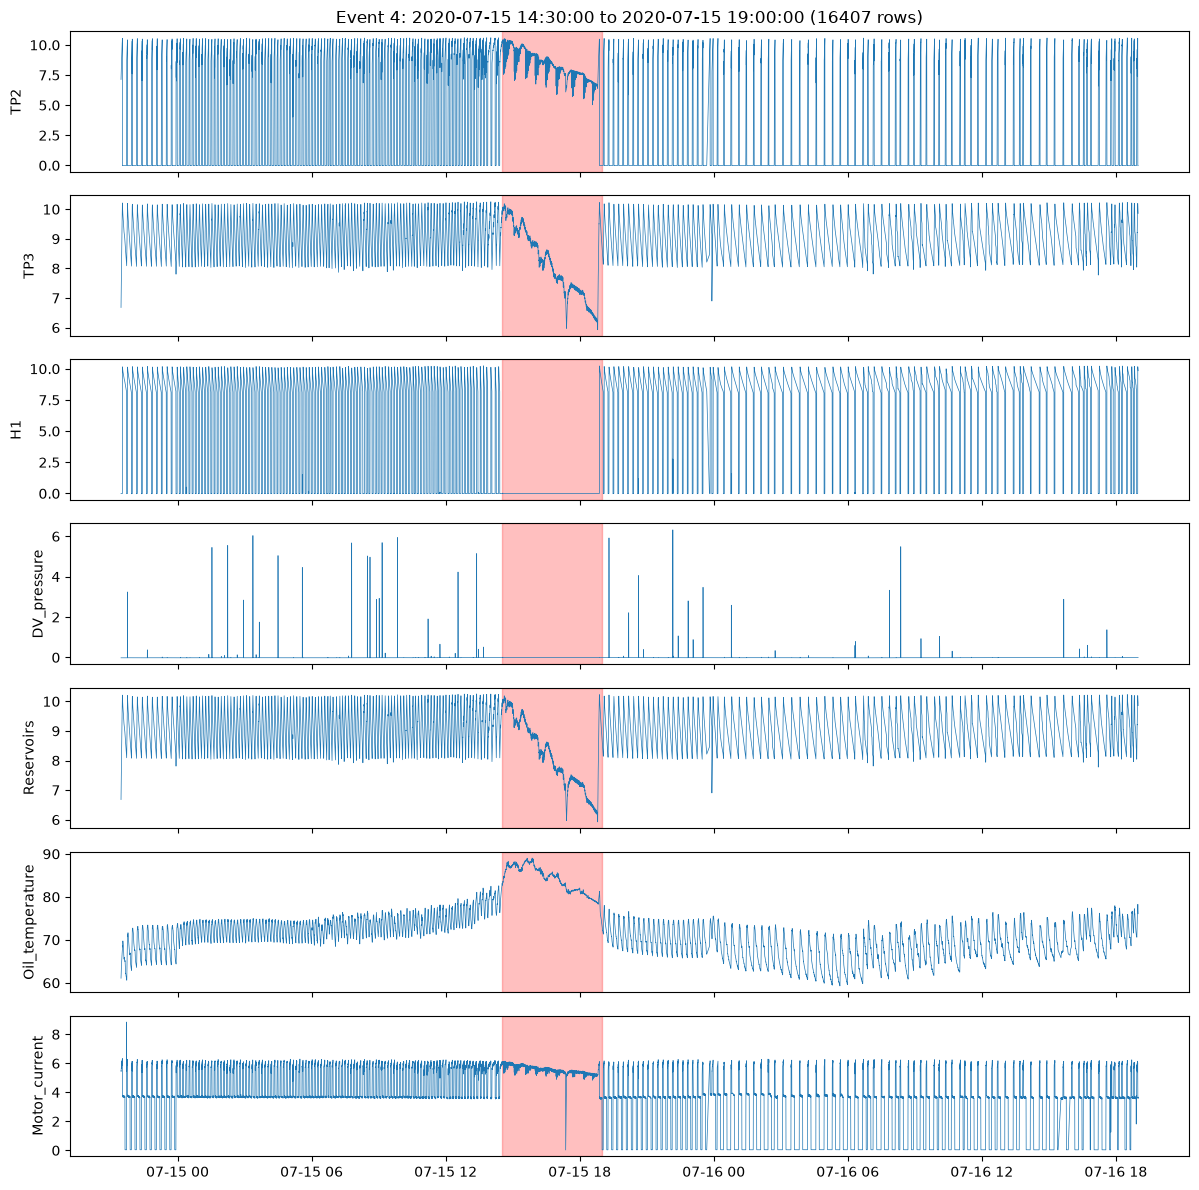

In [5]:
for w in windows:
    seg = df[(df["timestamp"] >= w.start - HORIZON) & (df["timestamp"] <= w.end + HORIZON)]
    fig, axes = plt.subplots(len(ANALOG_COLUMNS), 1, figsize=(12, 12), sharex=True)
    for ax, col in zip(axes, ANALOG_COLUMNS, strict=True):
        ax.plot(seg["timestamp"], seg[col], lw=0.5)
        ax.axvspan(w.start, w.end, color="red", alpha=0.25)
        ax.set_ylabel(col)
    axes[0].set_title(f"Event {w.id}: {w.start} to {w.end} ({len(seg)} rows)")
    plt.tight_layout()
    plt.show()

## Digital signal states

                 share_on  share_on_in_failure_windows
COMP                0.837                        0.004
DV_eletric          0.161                        0.995
Towers              0.920                        0.502
MPG                 0.833                        0.004
LPS                 0.003                        0.024
Pressure_switch     0.991                        0.995
Oil_level           0.904                        0.999
Caudal_impulses     0.937                        0.999


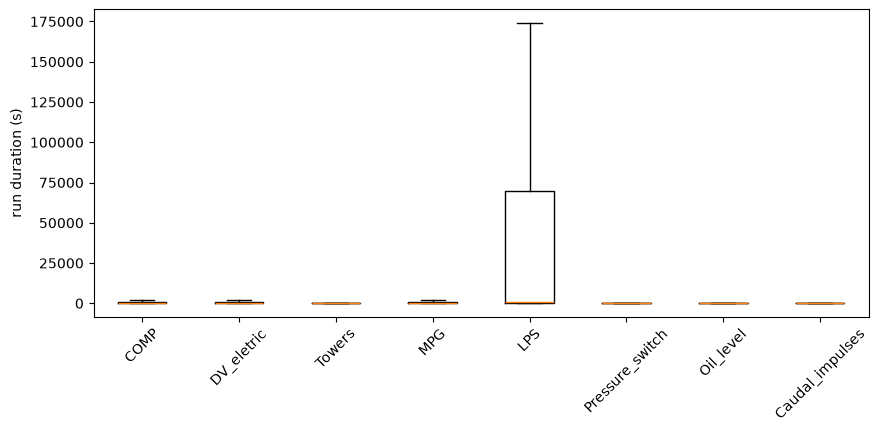

In [6]:
state = pd.DataFrame({
    "share_on": df[list(DIGITAL_COLUMNS)].mean(),
    "share_on_in_failure_windows": df.loc[df["label"] == FAILURE, list(DIGITAL_COLUMNS)].mean(),
})
print(state.round(3))
runs = {}
for col in DIGITAL_COLUMNS:
    run_id = (df[col] != df[col].shift()).cumsum()
    runs[col] = df.groupby(run_id)["timestamp"].agg(lambda t: (t.iloc[-1] - t.iloc[0]).total_seconds() + 10)
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([runs[c] for c in DIGITAL_COLUMNS], tick_labels=DIGITAL_COLUMNS, showfliers=False)
ax.set_ylabel("run duration (s)")
ax.tick_params(axis="x", rotation=45)
plt.show()